# 01 — Data exploration

**Replication of:** *Presence-absence estimation in audio recordings of tropical frog communities*
(Estrella Terneux, Nicolalde, Nicolalde & Merino-Viteri, [arXiv:1901.02495](https://arxiv.org/abs/1901.02495))

## 1. Purpose

A first audit of the three audio sources this replication will use. It answers four questions:

1. **What is actually on disk?** How many files, of what kind, organised how, and with what
   technical properties.
2. **Which part of it is the material the paper describes?** The article states what it recorded
   and what it analysed. The delivered collections have to be matched against that rather than
   assumed to be it.
3. **What does the material carry as labels, and where is that written?** Species, pond and date
   are of no use if they cannot be located, and the filenames are not the only place they hide.
4. **What cannot be reconstructed from what arrived?** Every gap between the article and the
   delivery is recorded as a limitation rather than filled in with a guess.

The three sources serve different purposes and are **never pooled**. Section 2 fixes the role of
each one before any measurement is taken.

> **This notebook is strictly read-only.** It reads file headers and the text of the companion
> files delivered alongside the audio — `.rtf` cue points, `.mat` segment files and `.xmp` metadata
> sidecars — but it never decodes audio samples. It does not move, rename, convert or write
> anything to the data directories.

Claims are tagged `[PAPER]` (stated in the article), `[SOURCE]` (stated by the paper's authors
in direct communication, and not written down anywhere in the data), `[OBSERVED]` (measured here,
and visible in the output of the cell above it) and `[INFERENCE]` (plausible but not provable from
the data).

## 2. Dataset sources

**What this section studies and why.** Three separate collections arrived from two different
places, and nothing about them can be measured before it is clear what each one is and where it
came from. This section fixes only that: what each collection is called here, who provided it, and
what its provider said about it. What each one turns out to be *good for* is a result of the
exploration, and is stated in section 7.

The audio lives outside the repository and is never copied into it. Each collection is bound to a
path constant named after its **origin or its contents**, never after a use:

| # | Constant | Folder | Provided by |
|---|---|---|---|
| 1 | `MENDELEY_CALL_DIR` | `Mendeley_5j852hzfjs_v1` | Published by the authors on Mendeley Data and downloaded from there |
| 2 | `PONDS_CALL_DIR` | `Cantos Pozas Yasuni Samael` | Sent directly by the researchers |
| 3 | `SPECIES_CALL_DIR` | `Cantos Especies` | Sent directly by the researchers |

### What each provider says about it

`[PAPER]` The first is the article's own published dataset, listed in its bibliography as reference
30: *"Labeled frog-call dataset of Yasuní National Park for training Machine Learning algorithms"*
(2018). The article states that the authors opened it to the research community, and it is hosted
on **Mendeley Data** — Elsevier's repository for published research datasets — at
<https://data.mendeley.com/datasets/5j852hzfjs/1>.

It was downloaded from there, and that is where its name comes from: the constant is called
`MENDELEY_CALL_DIR` and the folder `Mendeley_5j852hzfjs_v1` after the repository it was taken
from, the dataset identifier `5j852hzfjs` and the version `1`. Keeping the identifier in the name
is what makes the copy on disk traceable to a specific published release rather than to a private
hand-off.

The other two arrived by message from the researchers, who described them in their own words. Their
"first folder" is the species calls and their "second folder" is the pond recordings:

> `[SOURCE]` *The first folder contains the specific "clean" calls of the species that inhabit
> Yasuní and that are potentially present in the environmental recordings.*

> `[SOURCE]` *The second folder contains multiple recordings corresponding to two ponds in Yasuní,
> P1 and P2. The folders correspond to physical audio cassettes, and within each cassette folder
> there is a side A and a side B. Within each side, the audio files correspond either to P1 or
> to P2.*

The names chosen here follow suit: `MENDELEY_CALL_DIR` names a source, `PONDS_CALL_DIR` and
`SPECIES_CALL_DIR` name contents.

In [1]:
# Import libraries for file handling, metadata extraction, visualization and tables
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import soundfile as sf

# One global style, so no figure below has to repeat grid and spine settings.
sns.set_theme(style="ticks")


# Define paths to the external audio datasets
# The audio files are not stored inside the repository
MENDELEY_CALL_DIR = Path(r"C:\Users\USUARIO\Documents\Datos_Ranas\Mendeley_5j852hzfjs_v1")
PONDS_CALL_DIR = Path(r"C:\Users\USUARIO\Documents\Datos_Ranas\Cantos Pozas Yasuni Samael")
SPECIES_CALL_DIR = Path(r"C:\Users\USUARIO\Documents\Datos_Ranas\Cantos Especies")


# Verify that the dataset directories exist before running the analysis
for path in (MENDELEY_CALL_DIR, PONDS_CALL_DIR, SPECIES_CALL_DIR):
    print(f"{'OK ' if path.is_dir() else 'MISSING'}  {path}")

print(f"\nsoundfile {sf.__version__} (libsndfile {sf.__libsndfile_version__})")


# Configure pandas display options for easier visualization of summary tables
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 120)

OK   C:\Users\USUARIO\Documents\Datos_Ranas\Mendeley_5j852hzfjs_v1
OK   C:\Users\USUARIO\Documents\Datos_Ranas\Cantos Pozas Yasuni Samael
OK   C:\Users\USUARIO\Documents\Datos_Ranas\Cantos Especies

soundfile 0.14.0 (libsndfile 1.2.2)


## 3. File inventory

The purpose of this section is to create a structured inventory of all available files and their technical properties. The analysis only reads file metadata and does not modify, transform, or process the audio signals. The inventory is stored in a single `DataFrame`, with one row per file on disk.

### Metadata extraction

Audio metadata is read with `soundfile` without loading the audio samples. This provides the technical properties required for the inventory, including sample rate, channels, duration, frame count, and encoding subtype.

The three data sources contain different audio representations, so the inventory must support multiple formats and naming conventions.

The inventory also includes non-audio files such as annotations, metadata, waveform caches, and operating-system sidecars. These files are kept in the inventory to document the complete structure of the available data, while audio-specific analyses use the `is_audio` classification.

In [2]:
# libsndfile already reports the container in `format` ("WAV", "MP3") and the encoding
# in `subtype`, so neither needs a lookup table. Only the bit depth does: it is defined
# for PCM and float, and meaningless for the lossy codecs (GSM610, MPEG_LAYER_III),
# which are therefore absent from this map and resolve to None.
BIT_DEPTH_BY_SUBTYPE = {
    "PCM_S8": 8, "PCM_U8": 8, "PCM_16": 16, "PCM_24": 24, "PCM_32": 32,
    "FLOAT": 32, "DOUBLE": 64,
}

PROBE_FIELDS = ("format_name", "subtype", "sample_rate", "channels", "bit_depth",
                "bitrate_kbps", "duration_s", "frames", "header_error")


# reutilizable
def probe_audio_header(path: Path) -> dict:
    """Read an audio file's technical metadata without decoding its samples.

    Args:
        path (Path): Audio file to inspect.

    Returns:
        dict: The keys listed in ``PROBE_FIELDS``. If the header cannot be read, every
            value is None except ``header_error``, so a single bad file cannot abort an
            inventory of thousands.
    """
    result = {field: None for field in PROBE_FIELDS}

    try:
        info = sf.info(str(path))
        bit_depth = BIT_DEPTH_BY_SUBTYPE.get(info.subtype)
        result.update(
            format_name=info.format,
            subtype=info.subtype,
            sample_rate=info.samplerate,
            channels=info.channels,
            bit_depth=bit_depth,
            duration_s=info.duration,
            frames=info.frames,
        )

        # For compressed formats the bitrate is the informative number, not the bit depth.
        if bit_depth is None and info.duration:
            result["bitrate_kbps"] = round(path.stat().st_size * 8 / info.duration / 1000)

    except Exception as exc:
        result["header_error"] = f"{type(exc).__name__}: {exc}"

    return result

In [3]:
def is_macos_junk(name: str) -> bool:
    """Identify AppleDouble sidecars and Finder metadata files."""
    return name.startswith("._") or name == ".DS_Store"


def is_audio_file(name: str) -> bool:
    """Identify WAV and MP3 audio files."""
    # Some WAV files are missing the dot before the extension.
    return not is_macos_junk(name) and name.lower().endswith(("wav", ".mp3"))


def build_inventory(root: Path, dataset: str) -> pd.DataFrame:
    """Create a file inventory for one dataset.

    Args:
        root (Path): Directory to inspect recursively.
        dataset (str): Label assigned to the dataset.

    Returns:
        pandas.DataFrame: One row per file.
    """

    # Store the information collected for each file.
    rows = []

    # Recursively inspect all files inside the dataset directory.
    for path in sorted(root.rglob("*")):
        if not path.is_file():
            continue

        # Split the relative path into folder levels.
        parts = path.relative_to(root).parts

        # Store basic information about the file.
        row = {
            "dataset": dataset,
            "rel_path": str(path.relative_to(root)),
            "name": path.name,
            "top_folder": parts[0],
            "sub_folder": parts[1] if len(parts) > 2 else None,
            "ext": path.suffix.lower(),
            "size_bytes": path.stat().st_size,
            "macos_junk": is_macos_junk(path.name),
            "is_audio": is_audio_file(path.name),
        }

        # Add technical metadata only when the file is audio.
        if row["is_audio"]:
            row.update(probe_audio_header(path))

        # Add the completed file record to the inventory.
        rows.append(row)

    # Convert all collected records into a DataFrame.
    return pd.DataFrame(rows)


# Build the inventory for each data source and combine them into one table.
inventory = pd.concat(
    [
        build_inventory(MENDELEY_CALL_DIR, "mendeley_call"),
        build_inventory(PONDS_CALL_DIR, "ponds_call"),
        build_inventory(SPECIES_CALL_DIR, "species_call"),
    ],
    ignore_index=True,
)

# Display a basic summary of the resulting inventory.
print(f"{len(inventory)} files catalogued")
print(
    "containers:",
    sorted(inventory.loc[inventory.is_audio, "format_name"].dropna().unique())
)
print(
    "encodings:",
    sorted(inventory.loc[inventory.is_audio, "subtype"].dropna().unique())
)

2834 files catalogued
containers: ['MP3', 'WAV']
encodings: ['FLOAT', 'GSM610', 'MPEG_LAYER_III', 'PCM_16', 'PCM_24']


In [4]:
# Category is only used for the summary table below. Assigned in layers, each one
# overriding the previous: extension, then audio, then junk.
# Use a custom category instead of the raw extension because some files
# need semantic reclassification, such as macOS sidecars that may appear as WAV files.
inventory["category"] = inventory.ext.replace("", "(no extension)")
inventory.loc[inventory.is_audio, "category"] = "audio (wav)"
inventory.loc[inventory.is_audio & (inventory.ext == ".mp3"), "category"] = "audio (mp3)"
inventory.loc[inventory.macos_junk, "category"] = "macOS junk (._ , .DS_Store)"

file_types = (inventory.groupby(["dataset", "category"])
              .agg(files=("name", "size"), size_mb=("size_bytes", lambda s: s.sum() / 1e6))
              .round(1))
file_types

files  size_mb
dataset       category                                   
mendeley_call .mat                            10      0.0
              .rtf                           116      0.1
              audio (wav)                    114   9164.7
ponds_call    .pkf                            74      7.7
              .xmp                           744      3.4
              audio (wav)                    846  25863.5
              macOS junk (._ , .DS_Store)    910      7.2
species_call  audio (mp3)                     18     14.0
              audio (wav)                      2     44.1

`.XMP` and `.pkf` are Adobe Audition sidecars (metadata and waveform cache). Together with the macOS junk, they account for most of the file count in the environmental dataset but contain no audio. From this point, audio-specific analyses use only the `audio (wav)` rows, while sidecar metadata may be inspected separately when relevant.

In [5]:
audio = inventory[inventory.is_audio].copy()

print("audio files:", len(audio))
print("unreadable headers:", int(audio.header_error.notna().sum()))
print("total audio: %.1f hours" % (audio.duration_s.sum() / 3600))
audio.groupby("dataset").agg(files=("name", "size"),
                             hours=("duration_s", lambda s: s.sum() / 3600)).round(2)

audio files: 980
unreadable headers: 0
total audio: 126.5 hours


,files,hours
dataset,,
mendeley_call,114,25.66
ponds_call,846,100.67
species_call,20,0.18


## 4. Dataset 1 - Mendeley_5j852hzfjs_v1 (MENDELEY_CALL_DIR)

**What this section studies and why.** This is the primary corpus: the only source with enough
labelled material to support training. Before it can be used, four things have to be established
— how much audio exists per species, whether every recording carries its annotation, what the
annotations actually contain, and what the two folders that are not species hold. Each question below is asked as a table, and read immediately after.

This dataset contains eleven top-level folders: nine correspond to frog species, while `segment files` and `Unidentified Long Recordings` contain information or recordings that do not directly represent a species and are analyzed separately.

**Important:** the durations calculated here correspond to the **complete audio files stored inside each species folder**, not only to the portions in which a frog is calling. For example, a recording may last several minutes even if it contains only a few seconds of useful frog calls.

In [6]:
# This code keep only species-specific recordings and summarize file durations by species.

NON_SPECIES_FOLDERS = {"segment files", "Unidentified Long Recordings"}# These two folders are not species; they are handled separately.

mendeley_audio = audio[audio.dataset == "mendeley_call"] # From audio, keep only the rows where the dataset column is equal to "mendeley_call".
mendeley_species_audio = mendeley_audio[~mendeley_audio.top_folder.isin(NON_SPECIES_FOLDERS)].copy()# From mendeley_audio, keep only the 
#rows whose top_folder is not included in NON_SPECIES_FOLDERS, and create an independent copy.

mendeley_species_summary = (mendeley_species_audio.groupby("top_folder")
                   .agg(files=("name", "size"),
                        total_s=("duration_s", "sum"),
                        min_s=("duration_s", "min"),
                        median_s=("duration_s", "median"),
                        max_s=("duration_s", "max"))
                   .round(1))
mendeley_species_summary.index.name = "species folder"
mendeley_species_summary

,files,total_s,min_s,median_s,max_s
species folder,,,,,
Boana alfaroi,5,896.5,123.5,186.5,211.2
Boana cinerascens,8,1054.6,19.3,131.8,251.0
Boana lanciformis,7,1179.7,57.9,154.3,409.0
Dendropsophus bifurcus,10,2369.7,29.4,224.5,593.1
Engystomops petersi,12,4644.1,67.1,362.4,1018.6
Leptodactylus discodactylus,3,1529.7,401.2,500.0,628.5
Osteocephalus fuscifacies,5,414.4,53.6,85.1,117.7
Pristimantis conspicillatus,9,1896.7,80.8,227.3,307.5
Rhinella margaritifer,8,780.9,26.5,114.3,202.2


`[PAPER]` Table 1 reports **810.32 seconds of frog-call audio**, corresponding to **1495 individually delimited calls** used as the call corpus.

`[OBSERVED]` When the complete duration of the audio files stored in the nine species folders is added together, they contain approximately **4.1 hours of original recordings**. These recordings also include silence, environmental noise, and other portions that are not part of the delimited frog calls. Therefore, **4.1 hours of original recordings and 810.32 seconds of segmented calls measure different things**.

`[OBSERVED]` The Mendeley dataset contains species-specific folders for 9 of the 10 species reported in the paper. `Dendropsophus parviceps` (f09) is not represented by a species audio folder in this dataset. This structure can be seen in the table above.

`[PAPER]` Table 1 includes 38 calls and 40.1 s of labeled call audio for this species.

`[INFERENCE]` Material per species is very uneven — from 414 s for *Osteocephalus fuscifacies* to
4644 s for *Engystomops petersi*, a factor of eleven. Any later training step has to account for
this, but the imbalance that matters is the one in **call** seconds, not in recording seconds.

### Are the recordings paired with their annotations?

Every recording is supposed to come with an annotation file. This cross-tabulates the three file
types against the eleven top-level folders, which shows both the pairing and where it breaks.

In [7]:
# Summarize file extensions by top-level folder in the Mendeley dataset.
mendeley_files = inventory[inventory.dataset == "mendeley_call"]
pd.crosstab(mendeley_files.top_folder, mendeley_files.ext)

ext,.mat,.rtf,.wav
top_folder,,,
Boana alfaroi,0,5,5
Boana cinerascens,0,8,8
Boana lanciformis,0,7,7
Dendropsophus bifurcus,0,10,10
Engystomops petersi,0,12,12
Leptodactylus discodactylus,0,3,3
Osteocephalus fuscifacies,0,5,5
Pristimantis conspicillatus,0,9,9
Rhinella margaritifer,0,8,8


`[OBSERVED]` Species folders contain WAV recordings paired with RTF annotation files. The call-segment information is stored separately in the `segment files` folder, which contains 10 MAT files. This structure can be seen in the table above.

`[OBSERVED]` The pairing is exact in the nine species folders. It is **not** exact in
`Unidentified Long Recordings`, which holds 49 RTF against 47 WAV.

### What is inside an annotation file?

The table above confirms the RTF files exist, but not what they hold. This prints the beginning of
one of them.

In [8]:
# The .rtf files are cue-point annotations: start/end offsets in samples.
print((MENDELEY_CALL_DIR / "Boana alfaroi" / "1101.rtf").read_text(encoding="latin-1")[:420])

{\rtf1\ansi\ansicpg1252\deff0\deflang12298{\fonttbl{\f0\fnil Arial;}}
{\colortbl ;\red0\green0\blue128;}
\viewkind4\uc1\pard\cf1\f0\fs20 File: 1101.WAV
\par 
\par 1) Basic: 1 INICIO
\par 2) Basic: 2453437 FIN
\par 3) Basic: 2780125 INICIO
\par 4) Basic: 8176270 FIN
\par 
\par Cue ranges:\tab 0\tab |  CD title:\tab 1101
\par Cue points:\tab 4\tab |  Performer:\tab 
\par Cues total:\tab 4\tab |  Total time:\tab 0
\par 


`INICIO` / `FIN` are start/end offsets **in samples**. This is exactly the manual annotation the
paper describes: *"placing cue points signaling the start and end of the section containing calls"*.
These files, not the raw WAV durations, are what a future segmentation step should read.

### What is inside the `segment files` folder?

The RTF cue points are one route to the call boundaries. The `.mat` files are the other, and the
one the original authors worked from. This lists them before opening them.

In [9]:
# List the MATLAB segment files: one per species, names and sizes only.
segment_files = inventory[(inventory.dataset == "mendeley_call") & (inventory.ext == ".mat")]
print(f"{len(segment_files)} MATLAB segment files:\n")
print(segment_files[["name", "size_bytes"]].to_string(index=False))

10 MATLAB segment files:

                     name  size_bytes
       cantos_alfaroi.mat        1141
      cantos_bifurcus.mat        1380
   cantos_cinerascens.mat        1785
cantos_conspicillatus.mat        1990
 cantos_discodactylus.mat        2834
   cantos_fuscifacies.mat         912
   cantos_lanciformis.mat        1324
  cantos_margaritifer.mat        1224
     cantos_parviceps.mat         997
       cantos_petersi.mat        2973


Ten `.mat` files for ten species — **including `cantos_parviceps.mat`, which has no WAV folder.**



### What do the segment files actually store?

Listing the files gives their names and sizes only. This opens each one with `scipy.io.loadmat`
and reports the variables it contains, **without yet reading their values** — the goal here is to
learn the structure, not to draw conclusions from it.

In [10]:
from scipy.io import loadmat

# Inspect the MAT files to verify what call-segment information they contain.
for name in segment_files["name"]:
    path = MENDELEY_CALL_DIR / "segment files" / name
    data = loadmat(path)

    # Ignore internal MATLAB metadata and show only stored variables.
    variables = {
        key: value.shape
        for key, value in data.items()
        if not key.startswith("__")
    }

    print(name, variables)

cantos_alfaroi.mat {'cantos': (5, 3), 'duracion_sec': (1, 1)}


cantos_bifurcus.mat {'cantos': (10, 3), 'duracion_sec': (1, 1)}
cantos_cinerascens.mat {'cantos': (8, 3), 'duracion_sec': (1, 1)}
cantos_conspicillatus.mat {'cantos': (9, 3), 'duracion_sec': (1, 1)}
cantos_discodactylus.mat {'cantos': (3, 3), 'duracion_sec': (1, 1)}
cantos_fuscifacies.mat {'cantos': (5, 3), 'duracion_sec': (1, 1)}
cantos_lanciformis.mat {'cantos': (7, 3), 'duracion_sec': (1, 1)}
cantos_margaritifer.mat {'cantos': (7, 3), 'duracion_sec': (1, 1)}
cantos_parviceps.mat {'cantos': (9, 3), 'duracion_sec': (1, 1)}
cantos_petersi.mat {'cantos': (12, 3), 'duracion_sec': (1, 1)}


`[OBSERVED]` Every `.mat` file stores the same two variables: `cantos`, with one row per source
recording, and `duracion_sec`, a single `(1, 1)` scalar.

`[OBSERVED]` For eight species the number of rows in `cantos` matches the WAV count in the first
table of this section. Two do not:

| Segment file | Recordings described | WAV files on disk |
|---|---|---|
| `cantos_margaritifer.mat` | 7 | 8 |
| `cantos_parviceps.mat` | 9 | **none — the species has no folder** |

`[INFERENCE]` The segment files therefore describe material that is not all present in this
release. For `Dendropsophus parviceps` (f09) the annotation survived but the audio did not. For *R. margaritifer* one recording
on disk is not covered by the segmentation, or the eighth file was added later.

### Reading the stored values

`[OBSERVED]` The shapes alone do not verify Table 1: the call boundaries live inside `cantos` and
the total duration inside `duracion_sec`. The cell below prints those values.

**How to read the output.** The shape `(5, 3)` reported above for `cantos_alfaroi.mat` means five
rows and three columns: **one row per recording**, three fields per row. Unpacked, a single row
looks like this:

```text
cantos                          shape (5, 3)  ->  5 recordings x 3 fields
│
├── column 1 → source path      "D:\...\Hypsiboas Alfaroi\1101.WAV"
│
├── column 2 → call matrix      shape (N, 2)  ->  N calls x [start, end]
│              │
│              ├── call 1  → [ 20598,  37356]
│              ├── call 2  → [173184, 189942]
│              └── ...
│
└── column 3 → sample rate      44100 Hz   (44100 or 48000, depending on the recording)
```

**What counts as a call.** Each `[start, end]` pair in column 2 delimits **one vocalisation** — a
single call, not a passage that happens to contain several. The number of rows in that matrix is
therefore the number of calls in that recording.

That is what connects the two cells: the **row count of `cantos`** answers *how many recordings*,
and the **total number of rows across every call matrix** answers *how many calls*.

`[INFERENCE]` If that reading is correct, summing those rows per species should reproduce the call
counts in the paper's Table 1. This notebook does not compute that sum yet, so the equivalence
remains a hypothesis — written down here precisely so that a later check has something to falsify.

The offsets are positions in **samples**, not seconds, so dividing them by the 44100 Hz of column 3
is what turns a boundary into a duration.

The output below is deliberately raw and long (~1700 lines). It is the unabridged evidence,
printed before any aggregation, so that every count derived later can be traced back to it.

In [11]:
from scipy.io import loadmat

# Inspect the values stored in the MAT files to understand the call boundaries.

for name in segment_files["name"]:
    path = MENDELEY_CALL_DIR / "segment files" / name
    data = loadmat(path)

    print("\n", name)
    print("cantos:")
    print(data["cantos"])
    print("duracion_sec:")
    print(data["duracion_sec"])


 cantos_alfaroi.mat
cantos:
[[array(['D:\\Proyecto Ranas\\Experimento\\cantos por especie\\Hypsiboas Alfaroi\\1101.WAV'],
        dtype='<U75')
  array([[  20598,   37356],
         [ 173184,  189942],
         [ 449250,  467772],
         [ 815280,  836448],
         [1135446, 1156614],
         [1408866, 1428270],
         [1830462, 1847220],
         [2201784, 2219424],
         [3003582, 3024750],
         [3680958, 3702126],
         [4184580, 4204866],
         [4659096, 4679382],
         [4997784, 5017188],
         [5405268, 5422908],
         [5694564, 5712204],
         [6073824, 6090582],
         [6446910, 6467196],
         [6947886, 6967290],
         [7335966, 7357134],
         [7801662, 7822830],
         [8128884, 8150052]], dtype=int32) array([[44100]], dtype=uint16)]
 [array(['D:\\Proyecto Ranas\\Experimento\\cantos por especie\\Hypsiboas Alfaroi\\1102.WAV'],
        dtype='<U75')
  array([[  86771,  108821],
         [ 503075,  523361],
         [1218377, 1240427

`[OBSERVED]` Each row of `cantos` holds three fields: the **source WAV path**, an **N x 2 array of
start/end offsets in samples**, and the **sample rate** (44100).

`[OBSERVED]` The `.rtf` and `.mat` annotations are **not** two copies of the same information. For
`1101.WAV`, the RTF printed earlier in this section carries 4 cue points — that is, **2 sections** —
while `cantos_alfaroi.mat` stores **21 intervals** for that same recording.

`[INFERENCE]` The two describe the same audio at different granularities. The RTF marks the coarse
*sections containing calls* that the paper describes (*"placing cue points signaling the start and
end of the section containing calls"*), and the MAT marks the **individual calls** inside them.
Comparing the two printed outputs by hand supports this: the RTF sections span 1–2453437 and
2780125–8176270 samples, and all 21 MAT intervals fall inside them. **Only the MAT files are at the
granularity Table 1 counts** — the RTF cue points cannot be used to reproduce a call count.

`[OBSERVED]` The stored paths are absolute paths from the original authors' machine, of the form
`D:\Proyecto Ranas\Experimento\cantos por especie\Hypsiboas Alfaroi\1101.WAV`. They use
**`Hypsiboas`**, the superseded genus for what the folders now call *Boana*.

`[OBSERVED]` `duracion_sec` is one float per species, not one per recording.

### Rebuilding Table 1

Everything needed is now in hand: the row count of each call matrix gives the number of calls, and
`duracion_sec` gives the seconds. Putting the paper's published values beside the ones recovered
from the segment files answers the question this section opened with — **does the released corpus
reproduce the table the study reports?**

Read the column names literally. `mat_calls` and `mat_seconds` are **what the annotation declares**,
not what was measured from audio: both are read out of the `.mat` file. Whether the audio behind
them exists is a separate question, which `wav_referenced` and `wav_on_disk` answer by checking
every recording a segment file names against the WAV files actually present.

In [12]:
# Table 1 of the paper, plus the segment file that should reproduce each row.
# The pairing is written out instead of matched by name, because the spellings differ
# ("cantos_margaritifer.mat" on disk against "Rhinella margaritifera" in the paper).
PAPER_SPECIES = pd.DataFrame(
    [("f01", "Boana alfaroi", 98, 44.70, "cantos_alfaroi.mat"),
     ("f02", "Dendropsophus bifurcus", 103, 53.10, "cantos_bifurcus.mat"),
     ("f03", "Boana cinerascens", 169, 105.50, "cantos_cinerascens.mat"),
     ("f04", "Pristimantis conspicillatus", 186, 78.00, "cantos_conspicillatus.mat"),
     ("f05", "Leptodactylus discodactylus", 330, 146.30, "cantos_discodactylus.mat"),
     ("f06", "Osteocephalus fuscifacies", 50, 23.52, "cantos_fuscifacies.mat"),
     ("f07", "Boana lanciformis", 97, 57.70, "cantos_lanciformis.mat"),
     ("f08", "Rhinella margaritifera", 108, 124.20, "cantos_margaritifer.mat"),
     ("f09", "Dendropsophus parviceps", 38, 40.10, "cantos_parviceps.mat"),
     ("f10", "Engystomops petersi", 316, 137.20, "cantos_petersi.mat")],
    columns=["code", "species", "paper_calls", "paper_seconds", "segment_file"])

# Every WAV in the Mendeley dataset, to check whether the audio a segment file names is here.
wavs_on_disk = {name.lower() for name in mendeley_files.loc[mendeley_files.is_audio, "name"]}


def read_segment_file(filename: str) -> dict:
    """Read what one .mat segment file declares.

    Args:
        filename (str): File name inside the `segment files` folder.

    Returns:
        dict: Delimited calls, stored duration, sample rates, and how many of the
            recordings the file references are actually present on disk.
    """
    data = loadmat(MENDELEY_CALL_DIR / "segment files" / filename)
    rates = {int(rate[0][0]) for _, _, rate in data["cantos"]}
    names = [Path(str(path[0]).replace("\\", "/")).name for path, _, _ in data["cantos"]]

    return {"mat_calls": sum(calls.shape[0] for _, calls, _ in data["cantos"]),
            "mat_seconds": float(data["duracion_sec"][0][0]),
            "mat_hz": "/".join(str(hz) for hz in sorted(rates)),
            "wav_referenced": len(names),
            "wav_on_disk": sum(name.lower() in wavs_on_disk for name in names)}


measured = pd.DataFrame([read_segment_file(f) for f in PAPER_SPECIES.segment_file])
table1 = PAPER_SPECIES.join(measured)
table1["calls_diff"] = table1.mat_calls - table1.paper_calls
table1["seconds_diff"] = (table1.mat_seconds - table1.paper_seconds).round(2)

VALUE_COLS = ["species", "paper_calls", "mat_calls", "calls_diff",
              "paper_seconds", "mat_seconds", "seconds_diff",
              "mat_hz", "wav_referenced", "wav_on_disk"]
COUNT_COLS = ["paper_calls", "mat_calls", "calls_diff", "wav_referenced", "wav_on_disk"]

comparison = table1.set_index("code")[VALUE_COLS]

# Totals row. The two difference columns are recomputed from the totals rather than
# summed, because the per-row differences are already rounded.
totals = comparison.sum(numeric_only=True).to_frame("TOTAL").T
totals["calls_diff"] = totals.mat_calls - totals.paper_calls
totals["seconds_diff"] = totals.mat_seconds - totals.paper_seconds
totals[["species", "mat_hz"]] = ""                        # text columns do not add up

comparison = pd.concat([comparison, totals[VALUE_COLS]]).round(2)
comparison[COUNT_COLS] = comparison[COUNT_COLS].astype(int)  # concat had made them float

print(f"exact match on calls: {table1.calls_diff.eq(0).sum()}/10 species\n")
comparison

exact match on calls: 4/10 species



,species,paper_calls,mat_calls,calls_diff,paper_seconds,mat_seconds,seconds_diff,mat_hz,wav_referenced,wav_on_disk
f01,Boana alfaroi,98,98,0,44.70,44.72,0.02,44100,5,5
f02,Dendropsophus bifurcus,103,99,-4,53.10,42.51,-10.59,44100/48000,10,10
f03,Boana cinerascens,169,169,0,105.50,105.47,-0.03,44100/48000,8,8
f04,Pristimantis conspicillatus,186,186,0,78.00,77.94,-0.06,44100,9,9
f05,Leptodactylus discodactylus,330,340,10,146.30,120.28,-26.02,44100/48000,3,3
f06,Osteocephalus fuscifacies,50,54,4,23.52,26.10,2.58,44100/48000,5,5
f07,Boana lanciformis,97,101,4,57.70,57.84,0.14,44100,7,7
f08,Rhinella margaritifera,108,96,-12,124.20,111.74,-12.46,48000,7,7
f09,Dendropsophus parviceps,38,51,13,40.10,43.34,3.24,44100,9,1
f10,Engystomops petersi,316,316,0,137.20,137.23,0.03,44100/48000,12,12


`[OBSERVED]` **Four of the ten species reproduce Table 1 exactly.** `f01`, `f03`, `f04` and `f10`
agree on the call count and, to within 0.1 s, on the duration — *Boana alfaroi*, for instance, 98
calls in both and 44.72 s against 44.70 s.

`[INFERENCE]` An agreement that tight on four independent rows is not coincidence. These `.mat`
files are, in substance, the source Table 1 was computed from.

`[OBSERVED]` **The other six do not agree.** The totals come to **1510 calls and 767.18 s** (the `TOTAL` row) against
the paper's **1495 calls and 810.32 s** — 15 calls too many and 43 s too few. The disagreements run
in both directions (`f05` has 10 calls more than the paper, `f08` has 12 fewer), so this is neither
a uniform offset nor a rounding artefact.

`[INFERENCE]` The published Mendeley release is therefore **not the exact snapshot that produced
Table 1**. The most economical explanation is that the segmentation kept being edited after the
table was generated. Nothing in the data says which version is correct, and this notebook does not
decide it — it records that the two disagree.

### Is the referenced audio present and readable?

Inside the Mendeley dataset, the `segment files` folder contains `.mat` files with annotations that
reference audio recordings stored in the species folders of the same collection. Each `.mat` file
lists the WAV files used for the annotated segments of a given species.

The following cross-check compares those references against the audio files actually present in the
dataset. For each referenced WAV file, it verifies whether the file exists and whether it can be
opened successfully as audio. This makes it possible to distinguish between recordings that are
available and readable, recordings that are referenced but missing, and files that exist but cannot
be read.

In [13]:
# Verify that all WAV files referenced by segment files exist and can be opened.

results = []

for mat_file in segment_files["name"]:
    cantos = loadmat(
        MENDELEY_CALL_DIR / "segment files" / mat_file
    )["cantos"]

    for row in cantos:
        wav_path = Path(str(row[0][0]).replace("\\", "/"))
        name = wav_path.name

        match = mendeley_files[
            mendeley_files.name.str.lower() == name.lower()
        ]

        if match.empty:
            results.append({
                "segment_file": mat_file,
                "file": name,
                "status": "missing"
            })

        else:
            try:
                info = sf.info(MENDELEY_CALL_DIR / match.rel_path.iloc[0])

                results.append({
                    "segment_file": mat_file,
                    "file": name,
                    "status": "ok",
                    "sample_rate": info.samplerate,
                    "duration_s": info.duration
                })

            except Exception as e:
                results.append({
                    "segment_file": mat_file,
                    "file": name,
                    "status": "unreadable",
                    "error": str(e)
                })

audio_check = pd.DataFrame(results)

print(audio_check.status.value_counts().to_string())
audio_check

status
ok         67
missing     8


,segment_file,file,status,sample_rate,duration_s
0,cantos_alfaroi.mat,1101.WAV,ok,44100.0,186.471859
1,cantos_alfaroi.mat,1102.WAV,ok,44100.0,211.214127
2,cantos_alfaroi.mat,1103.WAV,ok,44100.0,197.417846
3,cantos_alfaroi.mat,1105.WAV,ok,44100.0,177.890930
4,cantos_alfaroi.mat,1106.WAV,ok,44100.0,123.511134
5,cantos_bifurcus.mat,D-bifircus-D-parviceps-LS100120.WAV,ok,44100.0,105.790113
6,cantos_bifurcus.mat,Dbifurcus2.WAV,ok,48000.0,45.923333
7,cantos_bifurcus.mat,D-bifurcus-sc10743.wav,ok,44100.0,593.124717
8,cantos_bifurcus.mat,Drhodopeplusbifurcus2_Daniel1.WAV,ok,48000.0,29.376667
9,cantos_bifurcus.mat,LS100120.WAV,ok,44100.0,105.790113


`[OBSERVED]` Of the 75 recordings the ten segment files reference, **67 come back `ok` and 8 come
back `missing`** — and not one comes back `unreadable`. Every recording that is present opens
cleanly. The `sample_rate` column shows only 44100 Hz and 48000 Hz, the two rates the segment files
themselves declare in `mat_hz` above: **what the segmentation says about the audio matches the
audio itself.**

`[OBSERVED]` All 8 missing rows belong to `cantos_parviceps.mat`. Its only surviving recording is
`D-bifircus-D-parviceps-LS100120.WAV` — 44100 Hz, 105.79 s — and the `segment_file` column shows
that same recording listed a second time under `cantos_bifurcus.mat`, which is where it is filed on
disk. Two of the missing names, `LS100582_parviceps.WAV` and `LS100582_parviceps_01.WAV`, carry the
recording id `LS100582`; the remaining six leave no trace under any spelling.

`[INFERENCE]` So the answer to this heading, for `f09`, is *almost none*: one recording out of the
nine its annotation describes, and that one filed under a different species. The rest of the
annotation describes audio that was never published.

### Sampling rate

`[OBSERVED]` The sample rate stored in column 3 is **not uniform**: five species are entirely at
44100 Hz or 48000 Hz, and five mix both. The segmentation was assembled from recordings made at two
different rates.

`[INFERENCE]` This does not threaten the call band. Both rates put the Nyquist limit (22050 Hz and
24000 Hz) far above the upper bound of frog call frequencies the paper reports, so no call energy is
lost at either rate. It does matter for the arithmetic: a sample offset means a different instant
depending on which rate its recording used, so offsets must never be converted to seconds with a
single global constant.

### Are the boundaries usable?

Counting calls and confirming the audio exists still says nothing about whether the boundaries can
be *used*. Two things have to hold before a later step cuts audio with them.

**Containment.** Every interval must end inside its own recording: `end / sample_rate` must not
exceed the WAV's duration. An offset pointing past the end of a file would crash an extraction step
or, worse, silently return a shorter clip.

**Self-consistency.** `duracion_sec` claims a total for the species. Summing the file's own
intervals must reproduce it. This one needs no comparison with the paper — it asks only whether each
segment file agrees with itself.

In [14]:
# Two validity checks on the boundaries, before any of them is used to cut audio:
#   1. containment  - does every interval end inside its own recording?
#   2. self-consistency - does `duracion_sec` equal the sum of the file's own intervals?

checks = []

for mat_file in segment_files["name"]:
    data = loadmat(MENDELEY_CALL_DIR / "segment files" / mat_file)

    recordings_checked = 0
    calls_out_of_range = 0
    sum_of_intervals = 0.0

    for path, boundaries, rate in data["cantos"]:
        name = Path(str(path[0]).replace("\\", "/")).name
        sample_rate = int(rate[0][0])

        # Offsets are in samples, so each one is divided by its own recording's rate.
        sum_of_intervals += (boundaries[:, 1] - boundaries[:, 0]).sum() / sample_rate

        # Containment can only be checked where the audio is present.
        match = mendeley_files[mendeley_files.name.str.lower() == name.lower()]
        if not match.empty:
            recordings_checked += 1
            duration = sf.info(MENDELEY_CALL_DIR / match.rel_path.iloc[0]).duration
            calls_out_of_range += int((boundaries[:, 1] / sample_rate > duration).sum())

    checks.append({
        "segment_file": mat_file,
        "recordings_checked": recordings_checked,
        "calls_out_of_range": calls_out_of_range,
        "duracion_sec": round(float(data["duracion_sec"][0][0]), 2),
        "sum_of_intervals": round(sum_of_intervals, 2),
    })

validity = pd.DataFrame(checks)
validity["gap_s"] = (validity.duracion_sec - validity.sum_of_intervals).round(2)
print("recordings checked :", validity.recordings_checked.sum(),
      " | calls out of range:", validity.calls_out_of_range.sum())
validity

recordings checked :

 67  | calls out of range: 0


,segment_file,recordings_checked,calls_out_of_range,duracion_sec,sum_of_intervals,gap_s
0,cantos_alfaroi.mat,5,0,44.72,44.72,0.00
1,cantos_bifurcus.mat,10,0,42.51,41.72,0.79
2,cantos_cinerascens.mat,8,0,105.47,102.58,2.89
3,cantos_conspicillatus.mat,9,0,77.94,77.94,0.00
4,cantos_discodactylus.mat,3,0,120.28,114.36,5.92
5,cantos_fuscifacies.mat,5,0,26.10,24.94,1.16
6,cantos_lanciformis.mat,7,0,57.84,57.84,0.00
7,cantos_margaritifer.mat,7,0,111.74,102.66,9.08
8,cantos_parviceps.mat,1,0,43.34,43.34,0.00
9,cantos_petersi.mat,12,0,137.23,134.00,3.23


`[OBSERVED]` **Containment holds everywhere.** Across the 67 recordings whose audio is present, not
a single interval ends past the end of its file (`calls_out_of_range` is 0 in every row). The
boundaries are safe to cut with. The 8 missing *parviceps* recordings could not be checked, which
is why `recordings_checked` reads 1 for that row.

`[OBSERVED]` **Self-consistency does not hold everywhere.** Four segment files reproduce their own
`duracion_sec` exactly — `alfaroi`, `conspicillatus`, `lanciformis` and `parviceps`, all with
`gap_s` of 0.00. In the other six the stored total is **larger** than the sum of its own intervals,
by 0.79 s in `bifurcus` and up to **9.08 s** in `margaritifer`.

`[INFERENCE]` The gap is always positive, meaning that the stored `duracion_sec` is larger than the duration reconstructed from the current intervals. This indicates that the summary value and the current segment boundaries are not fully consistent with each other. Possible explanations include changes made to the segmentation after the duration was calculated, mismatches between released annotation files, or annotation/calculation errors. The available data is not enough to determine which explanation is correct.

### What is in `Unidentified Long Recordings`?

Two of the eleven top-level folders are not species. `segment files` has been dissected above; this
one has so far only been counted in passing, and leaving it unmeasured would mean ignoring most of
the audio in this dataset. The first question is the plainest one: how many files are there, of
what kind, and how long is the audio.

In [15]:
# What the folder contains, by file type, and what the filenames actually look like.
long_files = mendeley_files[mendeley_files.top_folder == "Unidentified Long Recordings"]
long_recordings = long_files[long_files.is_audio]

print(long_files.ext.value_counts().to_string())
print("\nfirst 20 names:")
print(long_files.name.sort_values().head(20).to_string(index=False))
print(f"\n{len(long_recordings)} recordings, {long_recordings.duration_s.sum() / 3600:.1f} h"
      f"  ({long_recordings.duration_s.sum() / mendeley_audio.duration_s.sum():.0%} of this dataset)")
print("sample rates :", sorted(long_recordings.sample_rate.astype(int).unique().tolist()), "Hz")

# Same statistics in both units: seconds match the rest of the notebook, minutes are readable.
stats = long_recordings.duration_s.describe().drop("count")
pd.DataFrame({"duration_s": stats.round(1), "duration_min": (stats / 60).round(2)})

ext
.rtf    49
.wav    47

first 20 names:
cc126A.rtf
cc126A.wav
cc126B.rtf
cc126B.wav
cc127A.rtf
cc127A.wav
cc127B.rtf
cc127B.wav
cc128A.rtf
cc128A.wav
cc128B.rtf
cc128B.wav
cc129A.rtf
cc129A.wav
cc129B.rtf
cc130A.rtf
cc130A.wav
cc130B.rtf
cc130B.wav
cc131A.rtf

47 recordings, 21.6 h  (84% of this dataset)
sample rates : [48000] Hz


,duration_s,duration_min
mean,1651.4,27.52
std,293.4,4.89
min,308.3,5.14
25%,1702.1,28.37
50%,1736.9,28.95
75%,1762.8,29.38
max,1825.7,30.43


`[OBSERVED]` The folder holds two file types and nothing else: **49 `.rtf` and 47 `.wav`**, the same
pairing as the species folders except that here there are two more annotations than recordings.

`[OBSERVED]` The names listed above share the pattern `cc` followed by three digits and the
letter `A` or `B`, followed by the file extension. The numbers run from `cc126` to `cc151` and
apparently appear in `A`/`B` pairs. No species name, locality, or specimen voucher is included in
the filenames.

`[SOURCE]` According to the clarification provided by the paper's authors, that structure is a
cassette number followed by a letter indicating the cassette side.

`[OBSERVED]` The 47 recordings hold **21.6 h — 84% of all the audio in this dataset**, against 4.1 h
in the nine species folders put together. They are all 48 kHz, and their median length is 1736.9 s,
**28.95 minutes**.

### Is the cassette structure complete?

If every filename is a cassette side, then the folder should hold two sides for each cassette from
`cc126` to `cc151` — 26 cassettes, 52 sides, each with a recording and an annotation. It does not:
there are 47 and 49, not 52 and 52. The check below asks two things at once: whether any filename
departs from the `ccNNN` + side shape, and which sides are absent from each file type.

In [16]:
# reutilizable
def missing_cassette_sides(present, first: int, last: int) -> list:
    """Cassette sides absent from a collection.

    Args:
        present (Iterable[str]): Side ids that are present, written like "cc126a".
        first (int): First cassette number that should exist.
        last (int): Last cassette number that should exist.

    Returns:
        list[str]: The expected sides that are missing, sorted.
    """
    expected = {f"cc{number}{side}" for number in range(first, last + 1) for side in "ab"}
    return sorted(expected - {str(side).lower() for side in present})


# Does every filename follow ccNNN + side, and is any cassette side missing?
sides = long_files.name.str.extract(r"(?i)^(cc\d{3})([AB])\.")
print("filenames not matching ccNNN + side:", int(sides[0].isna().sum()), "of", len(long_files))

# Range taken from the names printed above: cc126 through cc151, two sides each.
ids = (sides[0] + sides[1]).str.lower()
present = {ext: set(ids[long_files.ext == ext]) for ext in (".wav", ".rtf")}

print("cassette sides expected  : 52   (cc126 to cc151, two each)")
for ext in (".wav", ".rtf"):
    print(f"  sides with no {ext}   :", missing_cassette_sides(present[ext], 126, 151))
print("  sides with neither   :",
      missing_cassette_sides(present[".wav"] | present[".rtf"], 126, 151))

filenames not matching ccNNN + side: 0 of 96
cassette sides expected  : 52   (cc126 to cc151, two each)
  sides with no .wav   : ['cc129b', 'cc131a', 'cc132a', 'cc139b', 'cc150b']
  sides with no .rtf   : ['cc139b', 'cc150b', 'cc151b']
  sides with neither   : ['cc139b', 'cc150b']


`[OBSERVED]` **Every one of the 96 filenames matches `ccNNN` + side**, with no exceptions. The
naming is mechanical, which is what makes the missing entries below meaningful rather than a
parsing artefact.

`[OBSERVED]` Five sides have no recording (`cc129B`, `cc131A`, `cc132A`, `cc139B`, `cc150B`) and
three have no annotation (`cc139B`, `cc150B`, `cc151B`). Two of them — **`cc139B` and `cc150B` —
are missing from both**: those cassette sides are absent from this folder entirely, not merely
unpaired.


### Is there really no species label?

Calling the folder "unidentified" is the release's own label, not a measurement. The recordings
do not include species names in their filenames, but most have a corresponding `.rtf` annotation,
and in the species folders those files contain annotation information. If species information is
recorded anywhere for these cassette sides, the `.rtf` files are the most likely place to find it.

The cell below prints one annotation in full and then searches all 49 `.rtf` files for mentions of
the ten species studied in the paper. It also counts the sections delimited in each annotation to
characterize what other information these files contain.

In [17]:
# Do the annotations name a species, and what else do they delimit?
rtf_paths = sorted((MENDELEY_CALL_DIR / "Unidentified Long Recordings").glob("*.rtf"))
texts = [path.read_text(encoding="latin-1") for path in rtf_paths]

print(texts[0])          # one annotation in full, so nothing below rests on a truncated view

epithets = PAPER_SPECIES.species.str.split().str[-1].str.lower()
print("annotations naming one of the paper's species:",
      sum(any(e in text.lower() for e in epithets) for text in texts), "of", len(texts))

# One INICIO/FIN pair is one section. Offsets are samples, at the single rate printed above.
rate = long_recordings.sample_rate.iloc[0]
offsets = [[int(n) for n in re.findall(r"Basic: (\d+) (?:INICIO|FIN)", text)] for text in texts]
per_file = pd.Series([len(row) // 2 for row in offsets], index=[p.stem.lower() for p in rtf_paths])
minutes = pd.Series([(row[i + 1] - row[i]) / rate / 60
                     for row in offsets for i in range(0, len(row) - 1, 2)])

# Sections per annotation, with the product that turns the distribution into a total.
counts = per_file.value_counts().sort_index()
sections_table = pd.DataFrame({"annotations": counts.values,
                               "sections": counts.index.values * counts.values},
                              index=counts.index.rename("sections per annotation"))
sections_table.loc["TOTAL"] = sections_table.sum()
display(sections_table)

print("section length in minutes:")
print(minutes.describe().round(2).to_string())

{\rtf1\ansi\ansicpg1252\deff0\deflang3082{\fonttbl{\f0\fnil Arial;}}
{\colortbl ;\red0\green0\blue128;}
\viewkind4\uc1\pard\cf1\f0\fs20 File: cc126A.wav
\par 
\par 1) Basic: 528516 INICIO
\par 2) Basic: 28649996 FIN
\par 3) Basic: 29138196 INICIO
\par 4) Basic: 57302620 FIN
\par 5) Basic: 57829236 INICIO
\par 6) Basic: 85702579 FIN
\par 
\par Cue ranges:\tab 0\tab |  CD title:\tab cc126A
\par Cue points:\tab 6\tab |  Performer:\tab 
\par Cues total:\tab 6\tab |  Total time:\tab 0
\par 
\par }
 
annotations naming one of the paper's species: 0 of 49


,annotations,sections
sections per annotation,,
1,2,2
2,2,4
3,44,132
4,1,4
TOTAL,49,142


section length in minutes:
count    142.00
mean       9.44
std        1.87
min        1.88
25%        9.20
50%        9.50
75%        9.69
max       28.70


`[OBSERVED]` **Not one of the 49 annotations names any of the paper's ten species.** The folder is not
unlabelled through careless naming; it is unlabelled in its annotation too.

`[OBSERVED]` What the annotations do carry is a division of each side into sections: **142 in
total** across the 49 files, with 44 of them marking exactly three. The median section runs
**9.50 minutes**, against the 28.95-minute median of the recordings that contain them.

`[PAPER]` The article describes the material it analysed in exactly these terms, in §4.3, *Field
recordings analysis*:

> *"Ten GMMs were trained using all the labeled dataset, and applied to analyze 23.5 hours of audio
> in 50 WAV files with focus on presence-absence estimation."*

> *"Each file contained three 10-minute samples delimited using cue points to inform its position
> to the algorithm."*

`[INFERENCE]` These are then neither calls nor species. Three windows of about ten minutes marked
by cue points inside a longer recording is the sampling scheme the study describes, and the
annotation records where somebody decided to listen rather than what was heard. The measurements
line up with the description: **49 annotated files against the 50 the article reports**, 44 of them
marking exactly the three samples it mentions, at a median length half a minute short of the stated
ten. What this folder holds is the paper's test material, in the form the algorithm consumed it —
long recordings with cue points, not the samples cut out of them.

## 5. Dataset 2 - Cantos Pozas Yasuni Samael (PONDS_CALL_DIR)

**What this section studies and why.** This is the collection the task is defined on: the
presence-absence problem the paper poses is a question about these recordings, not about the
species folders. Nothing here is training material.

Four things have to be established before it can be used — how the collection is physically
organised, what each file *is* (they are not interchangeable), which pond each recording belongs
to, and how much of that is actually recoverable. Each question below is asked as a table and read
immediately after.

In [18]:
# Physical organisation: one folder per cassette, one subfolder per side.
ponds_audio = (audio[audio.dataset == "ponds_call"]
             .rename(columns={"top_folder": "cassette", "sub_folder": "side"})
             .copy())
ponds_audio["cassette_number"] = ponds_audio.cassette.str.extract(r"(\d+)").astype(int)

first, last = ponds_audio.cassette_number.min(), ponds_audio.cassette_number.max()
print("cassettes      :", ponds_audio.cassette.nunique(), f"(cc{first} to cc{last})")
print("cassette sides :", ponds_audio.groupby(["cassette", "side"]).ngroups)
print("audio files    :", len(ponds_audio))

# Reuses the helper written for the Mendeley dataset, on ids built from the folder names here.
sides_present = "cc" + ponds_audio.cassette_number.astype(str) + ponds_audio.side.str.lower()
print("\nsides missing between cc%d and cc%d:" % (first, last),
      missing_cassette_sides(sides_present, first, last))
print("side labels      :", sorted(ponds_audio.side.dropna().unique()))
print("audio extensions :", ponds_audio.ext.replace("", "(none)").value_counts().to_dict())

# The audio is not everything the folders contain: count every delivered file, not just
# the ones the inventory marked as audio. Named ponds_file_types because section 3 already
# binds the name file_types.
ponds_file_types = (
    inventory.loc[inventory.dataset == "ponds_call", "category"]
    .value_counts()
    .rename_axis("category")
    .reset_index(name="files")
)

print("\nevery file delivered with this collection, by type:")
display(ponds_file_types)

cassettes      : 45 (cc106 to cc150)


cassette sides : 89
audio files    : 846

sides missing between cc106 and cc150: ['cc150b']
side labels      : ['A', 'B']
audio extensions : {'.wav': 841, '(none)': 5}

every file delivered with this collection, by type:


,category,files
0,"macOS junk (._ , .DS_Store)",910
1,audio (wav),846
2,.xmp,744
3,.pkf,74


`[OBSERVED]` The collection is **45 cassettes and 89 sides**, spanning `cc106` to `cc150`, holding
846 audio files. Two sides per cassette would be 90, so exactly one is absent: **`cc150b`**.

`[INFERENCE]` A single missing side out of ninety is a gap in the digitisation or in the delivery,
not a structural difference. Nothing in the folder layout says which.

`[OBSERVED]` The sides are labelled only `A` and `B`, and every audio file is a WAV — except **five
that lost the dot before the extension**, which any glob on `*.wav` would silently skip.

`[OBSERVED]` **Audio is not all that was delivered.** Alongside the 846 recordings sit 744 `.xmp`
and 74 `.pkf` files — Adobe Audition sidecars — plus 910 macOS junk entries. Counted by file, the
audio is a minority of what the folders contain.

`[INFERENCE]` A `.pkf` is a waveform peak cache, a rendering artefact with no semantic content. An
`.xmp`, by contrast, is Adobe's metadata format: plain XML, written per file, and capable of
carrying whatever the operator typed into the editor. Its extension says how it is stored, not what
is in it, so nothing can be concluded about these 744 files until they are opened. They are opened
below.

### What is each file?

The 846 files are not 846 recordings of the same kind. Their names follow a scheme that encodes
what each one *is*, and the distinction matters because a full cassette side, a ten-minute sample
and a six-second excerpt cannot be pooled in any experiment.

The classifier below is written as a list of patterns rather than a chain of conditions, so that
adding a role later means adding a row. What each role turns out to be is read from the table, not
assumed from its name.

In [19]:
# Five files lost the dot before "wav", so the dot is optional in ENDS_WAV rather than
# repaired beforehand. Trailing "\s*" absorbs a stray space seen in one filename.
ENDS_WAV = r"\s*\.?wav$"
CASSETTE = r"^cc\d{3}[AB]"
POZA = r"[-_ ]*(?:poza\s?[12][-_])?_?"

# Order matters only for readability here: no filename matches two of these patterns.
ROLE_PATTERNS = [
    ("side master", re.compile(CASSETTE + ENDS_WAV, re.I)),
    ("SP sub", re.compile(CASSETTE + POZA + r"sp\d[a-z](?:_\d+)?" + ENDS_WAV, re.I)),
    ("SP base", re.compile(CASSETTE + POZA + r"sp\d" + ENDS_WAV, re.I)),
    ("LS recorder", re.compile(r"^ls\d+" + ENDS_WAV, re.I)),
]


# reutilizable
def classify_env_file(name: str) -> str:
    """Assign an environmental recording to a role based on its filename.

    Args:
        name (str): Bare filename.

    Returns:
        str: One of "side master", "SP base", "SP sub", "LS recorder", "unclassified".
    """
    for role, pattern in ROLE_PATTERNS:
        if pattern.match(name):
            return role
    return "unclassified"


ponds_audio["role"] = ponds_audio.name.map(classify_env_file)

# Duration and encoding together: the role names are only a guess until the numbers agree.
role_summary = (ponds_audio.groupby("role")
                .agg(files=("name", "size"),
                     hours=("duration_s", lambda s: s.sum() / 3600),
                     median_s=("duration_s", "median"),
                     median_min=("duration_s", lambda d: d.median() / 60),
                     rates=("sample_rate", lambda s: "/".join(str(int(r)) for r in sorted(set(s)))),
                     channels=("channels", lambda s: "/".join(str(int(c)) for c in sorted(set(s)))),
                     encodings=("subtype", lambda s: "/".join(sorted(set(s)))))
                .round(2)
                .sort_values("files", ascending=False))
display(role_summary)

# How many SP base files sit on a single cassette side, and on how many sides.
sp_per_side = (ponds_audio[ponds_audio.role == "SP base"]
               .groupby(["cassette", "side"]).size()
               .value_counts().sort_index()
               .rename_axis("SP base files on one side")
               .rename("number of cassette sides").to_frame())
sp_per_side.loc["TOTAL"] = sp_per_side.sum()
display(sp_per_side)

,files,hours,median_s,median_min,rates,channels,encodings
role,,,,,,,
SP sub,475,5.90,6.34,0.11,44100/48000,1,FLOAT/GSM610/PCM_16
SP base,262,42.03,581.99,9.70,44100/48000,1,GSM610/PCM_16
side master,88,41.89,1753.26,29.22,44100/48000,1,GSM610/PCM_16
LS recorder,19,10.69,1840.06,30.67,44100/48000,2,PCM_16/PCM_24
unclassified,2,0.17,308.32,5.14,44100,1,GSM610


,number of cassette sides
SP base files on one side,
1,1
2,3
3,81
4,3
TOTAL,88


`[OBSERVED]` The four roles separate cleanly by duration. **side master** has 88 files with a median
of 1753 s (29 min), one per side. **SP base** has 262 files with a median of 582 s, just under ten
minutes. **SP sub** has 475 files with a median of 6.34 s. **LS recorder** has 19 files of about
30 min.

`[OBSERVED]` The per-side table shows **81 of the 88 sides carry exactly three SP base files**,
with three sides carrying two, three carrying four and one carrying a single file.

`[INFERENCE]` Three samples of about ten minutes per cassette side is a sampling scheme, and the
`SP` in the filename is what marks them. `SP sub` files, at a median of 6.34 s, are excerpts taken
out of those samples rather than a parallel set.

`[OBSERVED]` **`LS recorder` is the only role with 2 channels**; every other role is mono. It is
also the only one that carries no cassette number in its name.

`[OBSERVED]` Encoding cuts across the roles: `GSM610` and `PCM_16` both
appear in `side master`, `SP base` and `SP sub`.

### Narrowing to the paper's material

Everything above describes the collection as delivered. From this point on the analysis is
restricted to the part of it the study actually used, for reasons that are written down rather than
assumed.

The first is the article's own description of its material, in §2.3, *Acoustic Recording Protocol*,
of Estrella Terneux, A., Nicolalde, D., Nicolalde, D., & Merino-Viteri, A. (2019),
*Presence-absence estimation in audio recordings of tropical frog communities*,
arXiv:1901.02495v1 [cs.SD]:

> `[PAPER]` *"The analog audio was transfered to digital audio in WAV format at 48000 kHz sampling
> rate using a USB digital audio converter in 2012."*

> `[PAPER]` *"Sound was archived in lossless WAV files in order to preserve the integrity of the
> audio."*

and, in §4.3, *Field recordings analysis*, the size and shape of the test set:

> `[PAPER]` *"Ten GMMs were trained using all the labeled dataset, and applied to analyze 23.5 hours
> of audio in 50 WAV files with focus on presence-absence estimation."*

> `[PAPER]` *"Each file contained three 10-minute samples delimited using cue points to inform its
> position to the algorithm."*

The second is what the researchers who provided the collection state about it:

> `[SOURCE]` *This collection contains multiple recordings corresponding to two ponds in Yasuní,
> P1 and P2. The folders correspond to physical audio cassettes, and within each cassette folder
> there is a side A and a side B. Within each side, the audio files correspond either to P1 or
> to P2.*

From the paper's description, two selection criteria are relevant here: the recordings should be
**lossless** and correspond to the **ten-minute samples**, identified above as the `SP base` role.
`GSM610` is a lossy codec, so files using that encoding are excluded. Sampling rate is not used as
a filter because recordings at 44.1 kHz can be resampled to 48 kHz later if needed; instead, the
rates of the selected files are reported below and compared with the 48 kHz transfer described in
the paper.

In [20]:
# The paper's material: lossless audio, and the ten-minute samples rather than the full
# sides or the excerpts cut out of them. Sample rate is not a criterion, because 44.1 kHz
# resamples to 48 kHz while lossy compression cannot be undone.
test_samples = ponds_audio[(ponds_audio.subtype != "GSM610")
                         & (ponds_audio.role == "SP base")].copy()

print("files    : %4d  ->  %d" % (len(ponds_audio), len(test_samples)))
print("hours    : %6.2f -> %.2f" % (ponds_audio.duration_s.sum() / 3600,
                                    test_samples.duration_s.sum() / 3600))
print("cassettes: %4d  ->  %d   (cc%d to cc%d)"
      % (ponds_audio.cassette_number.nunique(), test_samples.cassette_number.nunique(),
         test_samples.cassette_number.min(), test_samples.cassette_number.max()))
print("cassette sides that contribute a sample:",
      test_samples.groupby(["cassette", "side"]).ngroups)

# Does the encoding split run between cassettes, or inside them?
sp_base_all = ponds_audio[ponds_audio.role == "SP base"]
by_cassette = sp_base_all.groupby("cassette_number").subtype.agg(lambda s: "/".join(sorted(set(s))))
print("\nSP base encoding, by cassette:")
for encoding, group in by_cassette.groupby(by_cassette):
    print(f"  {encoding:10s} cc{group.index.min()}-cc{group.index.max()}  ({len(group)} cassettes)")

# Rates are reported, not required. Adding the paper's 48 kHz as a criterion should
# change nothing if these really are the files it describes.
print("\nsample rates found  :", sorted(test_samples.sample_rate.astype(int).unique().tolist()))
print("encodings found     :", sorted(test_samples.subtype.unique().tolist()))
print("with 48 kHz imposed :", (test_samples.sample_rate == 48000).sum(), "of",
      len(test_samples), "files")

files    :  846  ->  141
hours    : 100.67 -> 22.38
cassettes:   45  ->  25   (cc126 to cc150)
cassette sides that contribute a sample: 48

SP base encoding, by cassette:
  GSM610     cc106-cc125  (20 cassettes)
  PCM_16     cc126-cc150  (25 cassettes)

sample rates found  : [48000]
encodings found     : ['PCM_16']
with 48 kHz imposed : 141 of 141 files


`[OBSERVED]` The two criteria leave **141 files and 22.38 hours**, drawn from **25 cassettes**
running `cc126` to `cc150` and from 48 of their sides. The collection loses 705 of its 846 files and
roughly three quarters of its hours.

`[OBSERVED]` Among the ten-minute samples the encoding split is **clean by cassette**: every
`SP base` file in `cc106`–`cc125` is `GSM610` and every one in `cc126`–`cc150` is `PCM_16`, with no
cassette mixing the two. This holds for this role only — other roles do contribute lossless files
from earlier cassettes.

`[OBSERVED]` The file count matches exactly, and the 22.38 hours measured fall 1.12 hours short of
the 23.5 reported.

`[INFERENCE]` The shortfall is what the article's own arithmetic predicts: 141 nominal ten-minute
samples would be 23.5 hours, while the samples on disk have a median under ten minutes. The count
agreeing exactly, reached from a lossless requirement and a duration role alone, is what identifies
this as the study's test material.

### What is actually inside the sidecars?

The environmental collection includes 744 `.xmp` files stored alongside the recordings. These
sidecars may contain metadata associated with the audio, so they are inspected to determine what
information is preserved in the delivered material.

Before extracting any field automatically, one `.xmp` file is printed in full. This makes the
structure of the metadata visible first and allows the extraction rule to be based on what is
actually present in the file.

The `.pkf` files were not analyzed further because they are peak-cache files used to speed up waveform display, not descriptive metadata sidecars. Since the goal here is to recover information about the recordings, the `.xmp` files are the relevant source.

In [21]:
# Look before parsing: one sidecar, printed whole.
xmp_paths = sorted(path for path in PONDS_CALL_DIR.rglob("*.xmp")
                   if not path.name.startswith("._"))

print(len(xmp_paths), "sidecars found\n")
print(xmp_paths[0].name, "\n")
print(xmp_paths[0].read_text(encoding="utf-8", errors="replace"))

744 sidecars found

cc106A-Poza1_SP3.XMP 

<?xpacket begin="﻿" id="W5M0MpCehiHzreSzNTczkc9d"?>
<x:xmpmeta xmlns:x="adobe:ns:meta/" x:xmptk="Public XMP Toolkit Core 4.0">
   <rdf:RDF xmlns:rdf="http://www.w3.org/1999/02/22-rdf-syntax-ns#">
      <rdf:Description rdf:about=""
            xmlns:photoshop="http://ns.adobe.com/photoshop/1.0/">
         <photoshop:State>Orellana</photoshop:State>
         <photoshop:Country>Ecuador</photoshop:Country>
      </rdf:Description>
      <rdf:Description rdf:about=""
            xmlns:Iptc4xmpCore="http://iptc.org/std/Iptc4xmpCore/1.0/xmlns/">
         <Iptc4xmpCore:Location>Estación Científica Yasuni (PUCE), Poza 1</Iptc4xmpCore:Location>
      </rdf:Description>
      <rdf:Description rdf:about=""
            xmlns:expressionmedia="http://ns.microsoft.com/expressionmedia/1.0/">
         <expressionmedia:UserFields>
            <rdf:Bag>
               <rdf:li>ColectorȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄ=Samael D. Padilla</rdf:li>
               <rdf:li>Fech

`[OBSERVED]` The sidecar is not a rendering artefact. It is XML, and it carries descriptive fields
somebody typed in: a `photoshop:State` and `Country`, a set of `UserFields` holding a collector, a
date, a time and a free-text note — and, in `<Iptc4xmpCore:Location>`, the string
**"Estación Científica Yasuni (PUCE), Poza 1"**.

`[INFERENCE]` The pond is written in the `Location` field. That is one file, so it proves the field
exists rather than that it is populated everywhere; all 744 are read below.

### Do the sidecars name any species?

The printed sidecar showed a pond in `Location`, so the rest of its fields deserve the same
treatment before the collection is called unlabelled. The question is whether any of them names one
of the ten species the article models.

This search runs over **all 744 sidecars, not only the 141 belonging to the test samples**, and the
reason is the structure of the collection. A `SP sub` file
is an excerpt cut out of a `SP base` sample: the two are the same audio at different lengths. So a
species written on an excerpt is a statement about the ten-minute sample it came from, and looking
only at the sidecars of the 141 would miss it. Files are grouped back to their parent sample by
cassette side and `SP` number, which is what the naming scheme encodes.

In [22]:
def read_xmp_species(path: Path) -> list:
    """Return the species named in a sidecar's `Especie` fields.

    Args:
        path (Path): An .xmp sidecar file.

    Returns:
        list[str]: Distinct species names, lowercased. Empty when the field is absent.
    """
    text = path.read_text(encoding="utf-8", errors="replace")
    return sorted({match.group(1).strip().lower()
                   for match in re.finditer(r"<rdf:li>Especie[^=]*=([^<]*)</rdf:li>", text)
                   if match.group(1).strip()})


def sample_group(name: str) -> str | None:
    """The ten-minute sample a file belongs to: its cassette side plus SP number.

    Args:
        name (str): Bare filename.

    Returns:
        str | None: A key such as "cc126b_sp1", or None when the name has no SP number.
    """
    match = re.match(r"^(cc\d{3}[AB])[-_ ]*(?:poza\s?[12][-_])?_?(sp\d)", name, re.I)
    return f"{match.group(1)}_{match.group(2)}".lower() if match else None


# Look before parsing, as with Location. The sidecar printed earlier had no such field,
# so here is one that does, showing the UserFields block it lives in.
example = next(path for path in xmp_paths
               if "Especie" in path.read_text(encoding="utf-8", errors="replace"))
print("a sidecar that carries the field:", example.name)
for line in example.read_text(encoding="utf-8", errors="replace").splitlines():
    if "<rdf:li>" in line:
        print("   ", line.strip())

species_by_stem = {path.stem.lower(): read_xmp_species(path) for path in xmp_paths}
print("sidecars naming at least one species:",
      sum(1 for names in species_by_stem.values() if names), "of", len(species_by_stem))

# Attach the species to every audio file, and the sample each file belongs to.
labelled = ponds_audio.assign(
    stem=[Path(name).stem.lower() for name in ponds_audio.name],
    group=ponds_audio.name.map(sample_group))
labelled["species"] = labelled.stem.map(species_by_stem)

print("\nspecies named anywhere in the collection:")
print(labelled.explode("species").species.value_counts().rename_axis("species")
      .to_frame("files").to_string())

# A species written on an excerpt is evidence about the sample it was cut from.
species_by_group = (labelled.explode("species").dropna(subset=["species"])
                    .groupby("group").species.agg(lambda names: sorted(set(names))))

test_samples["stem"] = [Path(name).stem.lower() for name in test_samples.name]
test_samples["group"] = test_samples.name.map(sample_group)
test_samples["species_in_sample"] = test_samples.group.map(species_by_group)

print("\nof the", len(test_samples), "test samples:")
print("  own sidecar names a species        :",
      int(test_samples.stem.map(species_by_stem).str.len().gt(0).sum()))
print("  a species is named somewhere in the sample:",
      int(test_samples.species_in_sample.notna().sum()))

a sidecar that carries the field:

 cc125A-Poza1_SP1A.XMP


    <rdf:li>FamiliaȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄ=Hylidae</rdf:li>
    <rdf:li>GeneroȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄ=Dendropsophus</rdf:li>
    <rdf:li>EspecieȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄ=bifurcus</rdf:li>
    <rdf:li>ColectorȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄ=Samael D. Padilla</rdf:li>
    <rdf:li>FechaȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄ=09/02/2002</rdf:li>
    <rdf:li>HoraȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄ=20:53</rdf:li>
    <rdf:li>Notas̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄=Grabación de tesis Padilla, S. 2005. Actividad reproductiva de dos comunidades de anuros en el Parque Nacional Yasuní. Tesis de Licenciatura. Pontificia Universidad Católica del Ecuador. Escuela de Biología. Quito.</rdf:li>
    <rdf:li>FamiliaȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄ=Hylidae</rdf:li>
    <rdf:li>GeneroȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄ=Dendropsophus</rdf:li>
    <rdf:li>EspecieȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄ=bifurcus</rdf:li>
    <rdf:li>ColectorȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄ=Samael D. Padilla</rdf:li>
    <rdf:li>FechaȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄ=09/02/2002</rdf:li>
    <rdf:li>HoraȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄȄ

sidecars naming at least one species: 129 of 744

species named anywhere in the collection:
               files
species             
bifurcus          70
cinerascens       49
petersi            5
deridens           1
planiceps          1
boans              1
pentadactylus      1
fuscifacies        1



of the 141 test samples:
  own sidecar names a species        : 0
  a species is named somewhere in the sample: 91


`[OBSERVED]` **129 of the 744 sidecars name a species**, in an `Especie` field that no earlier cell
had reason to look at.

`[OBSERVED]` **No test sample carries a species on its own sidecar** — the field is empty on all 141.
It is the excerpts that carry it, and grouping each excerpt back to the sample it was cut from
reaches **91 of the 141 test samples**.

`[INFERENCE]` This is presence evidence for the task the article poses, sitting in the delivered
material and never mentioned by it. The article reports hand-labelling 18 samples for evaluation;
the sidecars name species on considerably more. What they give is weaker than a full annotation —
a species written on one six-second excerpt says that species was heard in that sample, and says
nothing about the ones that were not written down — so it is presence evidence, not
presence-absence.

`[OBSERVED]` The names are dominated by two species, `bifurcus` and `cinerascens`, with `petersi`
and `fuscifacies` appearing a handful of times. Four names — `deridens`, `planiceps`, `boans` and
`pentadactylus` — are not among the ten the article models.

`[INFERENCE]` A field filled in by the person who cut the excerpts, naming species outside the
study set, reads as working notes rather than a systematic annotation: written when something was
recognised, left blank otherwise. That is exactly why absence of a name cannot be read as absence
of the species.

`[INFERENCE]` In summary, the delivered metadata provides partial evidence of species presence, but
it does not reconstruct the complete presence-absence labels used for evaluation in the paper.
Species names can be recovered for some samples, but an unmentioned species cannot be interpreted
as absent. Therefore, the full presence-absence vector for each test sample is not available from
the delivered material.

### Continuing with the pond

The `Especie` field gives partial presence and no absence, so the labels the article evaluates
against are still missing. They are not necessarily lost: the 18 annotated samples exist, they were
simply not part of this delivery, and the researchers may yet provide them.

This possibility makes it relevant to continue with this section because pond assignment is necessary to reproduce the ecological analysis that the paper performs separately for Pond 1 and Pond 2. If the complete presence-absence labels become available later, having each sample correctly assigned to a pond will allow those results to be organized and compared in the same way as in the article. The Location field is therefore examined across all 744 sidecars to recover this information and assess how complete and consistent it is within the delivered material.

### Recovering the pond from the `Location` field

The rule follows directly from what was printed: find the `Location` element, and read a pond out of
it if one is stated. A file whose `Location` says nothing about a pond returns nothing — no default,
no guess.

In [23]:
# reutilizable
def read_xmp_pond(path: Path) -> str | None:
    """Read the pond a recording belongs to from its .xmp sidecar.

    Args:
        path (Path): An .xmp sidecar file.

    Returns:
        str | None: "P1" or "P2" when the Location field states one, otherwise None.
    """
    text = path.read_text(encoding="utf-8", errors="replace")

    location = re.search(
        r"<Iptc4xmpCore:Location>(.*?)</Iptc4xmpCore:Location>",
        text,
        re.S
    )

    if not location:
        return None

    pond = re.search(r"poza\s*([12])", location.group(1), re.I)

    return f"P{pond.group(1)}" if pond else None


pond_by_stem = {path.stem.lower(): read_xmp_pond(path) for path in xmp_paths}
print("sidecars stating a pond:", sum(pond is not None for pond in pond_by_stem.values()),
      "of", len(pond_by_stem))

# Attach to the test material by filename stem.
test_samples["stem"] = [Path(name).stem.lower() for name in test_samples.name]
test_samples["pond_xmp"] = test_samples.stem.map(pond_by_stem)

print("\nof the %d test samples, pond recovered:" % len(test_samples))
print(test_samples.pond_xmp.fillna("unknown").value_counts().to_string())

sidecars stating a pond: 649 of 744

of the 141 test samples, pond recovered:
pond_xmp
P1         71
P2         68
unknown     2


`[OBSERVED]` **649 of the 744 sidecars state a pond**, and on the test material the recovery is
near total: **139 of the 141 samples** get one, 71 for P1 and 68 for P2.

### Why do 95 sidecars state no pond?

649 of 744 is not all of them, and a gap of 95 is worth a look before the recovered labels are
trusted. Two questions decide how much it matters: whether the absence follows a pattern, and which
of the 141 test samples it touches.

The cell below asks both at once. It groups the sidecars that state no pond by the role of the
recording they belong to, shows what their `Location` field says instead, and then names the test
samples affected — those are the only ones that change what can be answered later.

In [24]:
def read_xmp_location(path: Path) -> str | None:
    """Return the raw Location string of a sidecar, whatever it happens to say.

    Args:
        path (Path): An .xmp sidecar file.

    Returns:
        str | None: The Location text, or None when the element is absent. Reads the
            same element as ``read_xmp_pond``, without interpreting it.
    """
    text = path.read_text(encoding="utf-8", errors="replace")
    match = re.search(r"<Iptc4xmpCore:Location>(.*?)</Iptc4xmpCore:Location>", text, re.S)
    return match.group(1).strip() if match else None


# Roles were already assigned to the audio in section 5; reuse them rather than re-deriving.
role_by_stem = {Path(name).stem.lower(): role
                for name, role in zip(ponds_audio.name, ponds_audio.role)}

without_pond = pd.DataFrame(
    [{"stem": path.stem.lower(),
      "role": role_by_stem.get(path.stem.lower(), "no audio file"),
      "location": read_xmp_location(path)}
     for path in xmp_paths if pond_by_stem[path.stem.lower()] is None])

print("sidecars stating no pond:", len(without_pond), "of", len(xmp_paths), "\n")
display(pd.crosstab(pd.Series(role_by_stem.get(p.stem.lower(), "no audio file")
                              for p in xmp_paths).rename("role"),
                    pd.Series(pond_by_stem[p.stem.lower()] is not None
                              for p in xmp_paths).rename("states a pond")))

print("what those Location fields say instead:")
print(without_pond.location.fillna("(no Location element)").value_counts().to_string())

print("\ntest samples left without a pond:")
with pd.option_context("display.max_colwidth", None):
    display(
        test_samples.loc[
            test_samples.pond_xmp.isna(),
            ["name", "stem"]
        ]
        .assign(
            location=lambda frame: frame.stem.map(
                {
                    p.stem.lower(): read_xmp_location(p)
                    for p in xmp_paths
                }
            )
        )
        .drop(columns="stem")
    )

sidecars stating no pond: 95 of 744 



states a pond,False,True
role,,
LS recorder,1,0
SP base,7,254
SP sub,4,388
no audio file,0,1
side master,82,6
unclassified,1,0


what those Location fields say instead:
location
Estación Científica Yasuní (PUCE)            43
Estación Científica Yasuni (PUCE), Pozas     34
Estación Científica Yasuni (PUCE), a Poza     8
Estación Científica Yasuni (PUCE), Poza       6
(no Location element)                         3
Estación Científica Yasuni (PUCE)             1

test samples left without a pond:


,name,location
1205,cc126B_SP3.wav,NaN
1897,cc135B_SP1.wav,Estación Científica Yasuní (PUCE)


`[OBSERVED]` The absence is not scattered: **82 of the 95 are `side master` files**. A side master is a whole cassette side, and the article records both ponds on the same
night — P1 at 20:50 and P2 at 01:50. One side therefore contains both, and no single pond can be
assigned to it. The metadata is not missing here; **it is correctly absent**, and the plural spelling
says the operator knew it. The gap disappears as a data-quality concern.

`[OBSERVED]` After excluding the 82 `side master` files, **13 sidecars remain without a specific
pond assignment**. These are distributed across 7 `SP base` files, 4 `SP sub` files, 1 `LS recorder`,
and 1 unclassified recording.

`[OBSERVED]` Two of those 13 belong to the test material: `cc126B_SP3.wav`, whose sidecar contains
no `Location` element, and `cc135B_SP1.wav`, whose `Location` names only the station. The remaining
11 occur outside the test set and are inspected separately to determine whether their missing pond
labels share another identifiable pattern.

### What are the other 13?

The side masters account for 82 of the 95, and their missing pond turned out to be correct rather
than absent. The remaining 13 have not been looked at yet.

Thirteen rows fit on a screen, so they are printed in full rather than summarised: the filename, the
cassette and side they sit on, the role, what their `Location` actually says, whether the filename
states a pond, and the audio properties.

In [25]:
# Everything that might explain the 13: what the sidecar says, what the filename says,
# and what the audio is.
location_by_stem = {path.stem.lower(): read_xmp_location(path) for path in xmp_paths}

with_sidecar = ponds_audio.assign(
    stem=[Path(name).stem.lower() for name in ponds_audio.name],
    pond_in_name="P" + ponds_audio.name.str.extract(r"poza\s*([12])", flags=re.I)[0])
with_sidecar["pond_xmp"] = with_sidecar.stem.map(pond_by_stem)
with_sidecar["location"] = with_sidecar.stem.map(location_by_stem)
# Flag the rows that belong to the 141 samples the analysis is built on.
with_sidecar["test_sample"] = (with_sidecar.stem.isin(test_samples.stem)
                               .map({True: "yes", False: "no"}))

# A file with no sidecar at all is a different case, so only files that have one are kept.
thirteen = with_sidecar[with_sidecar.stem.isin(pond_by_stem)
                        & with_sidecar.pond_xmp.isna()
                        & (with_sidecar.role != "side master")]

print("gaps that are not side masters:", len(thirteen))
print("of those, the filename states a pond:", thirteen.pond_in_name.notna().sum())
print("encodings:", thirteen.subtype.value_counts().to_dict(), "\n")

with pd.option_context("display.max_colwidth", None):
    display(thirteen[["name", "test_sample", "cassette", "side", "role", "location",
                      "pond_in_name", "duration_s", "subtype"]]
            .sort_values(["cassette", "name"])
            .round(1)
            .reset_index(drop=True))

gaps that are not side masters: 13
of those, the filename states a pond: 7
encodings: {'GSM610': 8, 'PCM_16': 4, 'PCM_24': 1} 



,name,test_sample,cassette,side,role,location,pond_in_name,duration_s,subtype
0,cc117B-Poza1_SP2.wav,no,qcaz-cc117,B,SP base,"Estación Científica Yasuni (PUCE), a Poza",P1,598.0,GSM610
1,cc117B-Poza1_SP2A.wav,no,qcaz-cc117,B,SP sub,"Estación Científica Yasuni (PUCE), a Poza",P1,64.6,GSM610
2,cc117B-Poza2_SP1.wav,no,qcaz-cc117,B,SP base,"Estación Científica Yasuni (PUCE), a Poza",P2,575.3,GSM610
3,cc117B-Poza2_SP1A.wav,no,qcaz-cc117,B,SP sub,"Estación Científica Yasuni (PUCE), a Poza",P2,227.9,GSM610
4,cc117B-Poza2_SP3.wav,no,qcaz-cc117,B,SP base,"Estación Científica Yasuni (PUCE), a Poza",P2,585.6,GSM610
5,cc119A-Poza2_SP2.wav,no,qcaz-cc119,A,SP base,"Estación Científica Yasuni (PUCE), Poza",P2,396.0,GSM610
6,cc119B-Canto Indeterminado.wav,no,qcaz-cc119,B,unclassified,"Estación Científica Yasuni (PUCE), Poza",NaN,42.4,GSM610
7,cc123A-Poza2_SP2.wav,no,qcaz-cc123,A,SP base,"Estación Científica Yasuni (PUCE), Poza",P2,588.2,GSM610
8,LS100468.WAV,no,qcaz-cc126,B,LS recorder,NaN,NaN,2331.4,PCM_24
9,cc126B_SP3.wav,yes,qcaz-cc126,B,SP base,NaN,NaN,557.0,PCM_16


`[OBSERVED]` The 13 are not spread across the collection. They sit in **five cassettes** —
`cc117`, `cc119`, `cc123`, `cc126`, `cc135` — and in six sides between them.

`[OBSERVED]` They split cleanly by encoding, and the split matches what the `Location` field says.
The **8 `GSM610`** rows all carry a Location that gestures at a pond without naming one:
*"…(PUCE), a Poza"* or *"…(PUCE), Poza"*. The **5 PCM** rows carry either no `Location` element at
all or the station name alone.

`[OBSERVED]` **7 of the 13 state the pond in their filename**, and all seven are among the `GSM610`
rows — `cc117B-Poza1_SP2.wav` says P1, `cc119A-Poza2_SP2.wav` says P2, and so on.

`[INFERENCE]` For these seven files, the pond can still be recovered because it is stated explicitly in the filename, even though it is not specified in the sidecar’s Location field. Therefore, the issue is not that the pond information was lost, but that the different metadata sources for the same file do not contain the same level of detail.

`[OBSERVED]` **Six files still have no pond identified from either the sidecar or the filename.**
Four of them form two `SP base` / `SP sub` pairs: `SP1` with `SP1A` and `SP3` with `SP3A`.
The remaining two are `cc119B-Canto Indeterminado.wav` and `LS100468.WAV`.

`[INFERENCE]` In the paired cases, the `SP sub` is derived from the corresponding `SP base`, so
the missing pond label is repeated across two files that belong to the same underlying sample.
This means that the unresolved information is concentrated in fewer recording units than the raw
file count suggests.

`[OBSERVED]` Of the six files for which the pond remains unresolved, **two belong to the 141 test
samples**: `cc126B_SP3.wav` and `cc135B_SP1.wav`. Therefore, pond information is available for
**139 of the 141 test samples**, while these two remain explicitly unassigned.

### Do the filenames agree with the sidecars?

The pond now comes from a single source, and a single source cannot be checked against itself. Some
filenames state a pond too, written by hand and independently of the metadata, which makes them a
second opinion wherever both exist.

The comparison runs twice. First on the test material, which is what the analysis is built on, and
then on the whole collection — not to reintroduce the discarded half as evidence, but because a
method is validated on every case available, and far more filenames carry a pond outside the test
set than inside it.

In [26]:
# reutilizable
def compare_pond_sources(frame: pd.DataFrame) -> pd.DataFrame:
    """Line up the pond written in each filename against the one read from its sidecar.

    Args:
        frame (pandas.DataFrame): Rows carrying a ``name`` and a ``pond_xmp`` column.

    Returns:
        pandas.DataFrame: Only the rows where both sources state a pond, with the two
            values side by side and an ``agrees`` flag.
    """
    compared = frame.assign(
        pond_in_name="P" + frame.name.str.extract(r"poza\s*([12])", flags=re.I)[0])
    both = compared[compared.pond_in_name.notna() & compared.pond_xmp.notna()]
    return both.assign(agrees=both.pond_in_name == both.pond_xmp)


in_test = compare_pond_sources(test_samples)
print("test samples with a pond in both sources:", len(in_test), "of", len(test_samples),
      "- they agree in", int(in_test.agrees.sum()))

# `with_sidecar` was built above and already carries pond_xmp for every audio file.
# Which source states the pond, over the whole collection: a complete partition.
states_in_sidecar = with_sidecar.pond_xmp.notna()
states_in_name = with_sidecar.pond_in_name.notna()

pond_source = pd.Series("no source states it", index=with_sidecar.index)
pond_source[states_in_sidecar] = "the sidecar only"
pond_source[states_in_name] = "the filename only"
pond_source[states_in_sidecar & states_in_name] = "both sources"

coverage = (pond_source.value_counts()
            .reindex(["both sources", "the sidecar only",
                      "the filename only", "no source states it"])
            .rename_axis("the pond is stated by").to_frame("audio files"))
coverage.loc["TOTAL"] = coverage.sum()
display(coverage)

# Only the rows with two opinions can be checked against each other.
everywhere = compare_pond_sources(with_sidecar)
agreement = (everywhere.agrees.map({True: "the same pond", False: "a different pond"})
             .value_counts().rename_axis("the two sources give").to_frame("audio files"))
agreement.loc["TOTAL"] = agreement.sum()
display(agreement)

print("where they disagree:")
with pd.option_context("display.max_colwidth", None):
    display(everywhere.loc[~everywhere.agrees,
                           ["name", "test_sample", "pond_in_name", "pond_xmp", "subtype"]]
            .reset_index(drop=True))

test samples with a pond in both sources: 3 of 141 - they agree in 3


,audio files
the pond is stated by,
both sources,239
the sidecar only,409
the filename only,14
no source states it,184
TOTAL,846


,audio files
the two sources give,
the same pond,234
a different pond,5
TOTAL,239


where they disagree:


,name,test_sample,pond_in_name,pond_xmp,subtype
0,cc115B-Poza1_SP2.wav,no,P1,P2,GSM610
1,cc115B-Poza1_SP2A.wav,no,P1,P2,GSM610
2,cc116B-Poza1_SP2.wav,no,P1,P2,GSM610
3,cc116B-Poza1_SP2A.wav,no,P1,P2,GSM610
4,cc116B-Poza1_SP2B.wav,no,P1,P2,GSM610


`[OBSERVED]` Inside the test material the comparison is almost empty: **3 samples of 141 state a
pond in both places**, and all three agree. Three cases decide nothing on their own.

`[OBSERVED]` Across the whole collection **239 files state a pond in both places**, and **234
agree**. Five do not. The disagreements are also confined to material this analysis does not use.

`[OBSERVED]` The five disagreements are `GSM610` and none of them is a test sample. They fall on two
cassette sides, `cc115B` and `cc116B`, and all five belong to the same `SP2` group: the filename
says `Poza1` while the sidecar says P2.

`[INFERENCE]` Agreement in 234 of the 239 files where both sources state a pond shows a high level of consistency between the filename and the sidecar. The remaining five disagreements indicate that neither source should be assumed to be infallible in conflicting cases. Even so, the high level of agreement supports using the sidecar as the primary source for recovering the pond.


### How is the test material distributed?

With a pond on 139 of the 141 samples, the breakdown this section was meant to end with can finally
be produced: how much material each pond contributes, and how long its samples run.

,files,files_%,hours,hours_%
pond,,,,
P1,71.0,50.35,11.30,50.52
P2,68.0,48.23,10.79,48.22
unknown,2.0,1.42,0.28,1.26
TOTAL,141.0,100.00,22.38,100.00


,count,mean,std,min,25%,50%,75%,max
pond_xmp,,,,,,,,
P1,71.0,9.55,0.74,4.25,9.47,9.70,9.88,10.40
P2,68.0,9.52,0.99,2.04,9.39,9.67,9.88,10.44
unknown,2.0,8.47,1.16,7.65,8.06,8.47,8.88,9.28


samples shorter than 8 minutes: 3
          name  minutes
cc135A_SP4.wav     2.04
cc136B_SP3.wav     4.25
cc135B_SP1.wav     7.65
all 141 samples:
count    141.00
mean       9.52
std        0.88
min        2.04
25%        9.39
50%        9.68
75%        9.88
max       10.44


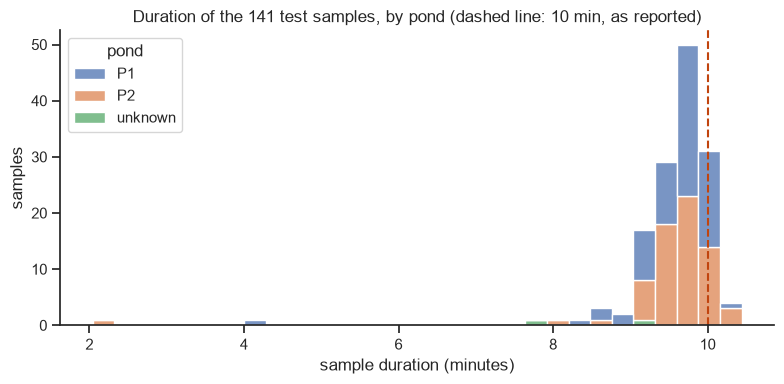

In [27]:
# How the test material splits between the two ponds, in files and in hours.
test_samples["minutes"] = test_samples.duration_s / 60
pond = test_samples.pond_xmp.fillna("unknown")

distribution = (test_samples.groupby(pond)
                .agg(files=("name", "size"), hours=("duration_s", lambda d: d.sum() / 3600))
                .rename_axis("pond"))
distribution["files_%"] = 100 * distribution.files / len(test_samples)
distribution["hours_%"] = 100 * distribution.hours / distribution.hours.sum()

# Totals from the samples themselves, not summed from rounded rows.
distribution.loc["TOTAL"] = [len(test_samples), test_samples.duration_s.sum() / 3600, 100.0, 100.0]
display(distribution[["files", "files_%", "hours", "hours_%"]].round(2))

# Sample length per pond, and overall.
display(test_samples.groupby(pond).minutes.describe().round(2))
# The describe above jumps from the minimum to the 25th percentile, so the short tail
# is not visible in it. Counted here instead of eyeballed off the histogram.
short = test_samples.minutes < 8
print("samples shorter than 8 minutes:", int(short.sum()))
print(test_samples.loc[short, ["name", "minutes"]]
      .sort_values("minutes").round(2).to_string(index=False))

print("all 141 samples:")
print(test_samples.minutes.describe().round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=test_samples.assign(pond=pond), x="minutes", hue="pond",
             bins=30, multiple="stack", ax=ax)
ax.axvline(10, color="#c1440e", linestyle="--")
ax.set(xlabel="sample duration (minutes)", ylabel="samples",
       title="Duration of the 141 test samples, by pond (dashed line: 10 min, as reported)")
sns.despine()
fig.tight_layout()
plt.show()

`[OBSERVED]` The two ponds are **almost exactly balanced**, and in both units at once: P1 holds
**71 samples (50.35%) and 11.30 hours (50.52%)**, P2 holds **68 samples (48.23%) and 10.79 hours
(48.22%)**. The 2 unassigned samples account for 1.42% of the files and 1.26% of the audio.

`[INFERENCE]` The percentages agreeing across files and hours means neither pond contributes
systematically longer samples. A per-pond result computed on this material would not need weighting
to correct for unequal effort, which is what the article's daily two-pond schedule would predict.

`[OBSERVED]` The samples are **not** ten minutes each. Over all 141 the mean is **9.52 minutes** and
the median **9.68**, with a spread from **2.04 to 10.44**. The histogram shows the bulk packed
between 9 and 10.5 minutes, with only **three samples below 8** — two of them far below, at 2.04
and 4.25 minutes.

`[OBSERVED]` The two ponds differ in consistency rather than in length: P1 has a standard deviation
of **0.74** and a shortest sample of **4.25 minutes**, while P2 spreads wider at **0.99** and holds
the shortest sample in the corpus at **2.04 minutes**. Their medians are within 0.03 minutes of each
other.

## 6. Dataset 3 - Cantos Especies (SPECIES_CALL_DIR)

**What this section studies and why.** This is the third and smallest collection, provided
separately by the researchers, who describe it in a single sentence:

> `[SOURCE]` *The folder contains the specific "clean" calls of the species that inhabit Yasuní and
> that are potentially present in the environmental recordings.*

That describes the **content** — isolated calls of the species one might expect to hear in the
material of section 5 — and says nothing about what the collection can be used for. The use has to
be measured, and two things decide it: how much material there is per species,
and what it is encoded as.

A small curated collection: **two files per species**, no exceptions. Unlike Dataset 1 the
filenames are clean and name exactly one species.

In [28]:
# Everything the folder holds, before narrowing to the audio: a reader cannot tell
# from `species_call_audio` alone whether anything non-audio was delivered with it.
species_call_file_types = (
    inventory.loc[inventory.dataset == "species_call", "category"]
    .value_counts()
    .rename_axis("category")
    .reset_index(name="files")
)

print("every file delivered with this collection, by type:")
display(species_call_file_types)

# How much material this collection holds per species, and in what container.
species_call_audio = audio[audio.dataset == "species_call"].copy()

species_call_summary = (species_call_audio.groupby("top_folder")
                     .agg(files=("name", "size"),
                          total_s=("duration_s", "sum"),
                          containers=("ext", lambda s: "/".join(sorted({e.lstrip(".") for e in s}))))
                     .round(1))
species_call_summary.index.name = "species folder"
species_call_summary

every file delivered with this collection, by type:


,category,files
0,audio (mp3),18
1,audio (wav),2


,files,total_s,containers
species folder,,,
Boana alfaroi,2,218.2,mp3
Boana cinerascens,2,16.9,mp3
Boana lanciformis,2,31.8,mp3
Dendropsophus bifurcus,2,37.3,mp3
Dendropsophus parviceps,2,27.7,mp3
Engystomops petersi,2,24.0,mp3
Leptodactylus discodactylus,2,38.9,mp3
Osteocephalus fuscifacies,2,166.5,wav
Pristimantis conspicillatus,2,53.3,mp3


`[OBSERVED]` The collection contains **ten species folders with exactly two files each**, with no
folder holding more or fewer files. Nine of the ten contain `mp3` files; only
*Osteocephalus fuscifacies* is provided as `wav`.

`[OBSERVED]` The amount of material per species is highly uneven, ranging from **16.9 s for**
***Boana cinerascens*** to **218.2 s for** ***Boana alfaroi***, a difference of roughly thirteen
times between the smallest and largest folders.

`[OBSERVED]` Two folder names do not correspond directly to dedicated species folders in the
Mendeley dataset: *Dendropsophus parviceps* and *Rhinella acutirostris*. The first is one of the
ten species modeled in the paper, but its labelled audio is largely missing from the delivered
Mendeley material. The second does not appear under that name in the paper, which instead models
*Rhinella margaritifera*.

`[INFERENCE]` The relationship between the *Rhinella acutirostris* recordings in Dataset 3 and the
*Rhinella margaritifera* class used in the paper cannot be resolved from the delivered material
alone. They should therefore remain separate at this stage rather than being merged under an
unsupported taxonomic assumption.

### Could it serve as training material?

The researchers describe clean calls of the species that might be present in the environmental
recordings, which is what a detector would want as examples. Whether these particular files can
play that part depends on two things the per-species table does not show.

The first is **size**: how these few minutes compare with the **nine species folders of the Mendeley
dataset** — Dataset 1, examined in section 4 — which hold the labelled frog calls a model would
otherwise learn from.

The second is **what the audio actually is**: the `.mp3` and `.wav` extensions name the container,
not the encoding inside it, and a file can be lossless or heavily compressed without the extension
saying so.

In [29]:
# This collection against the corpus that would train on it, and what the audio really is.
print("Dataset 3 totals: %d files, %.1f s (%.1f min)"
      % (len(species_call_audio), species_call_audio.duration_s.sum(), species_call_audio.duration_s.sum() / 60))
print("Dataset 1 species folders, for scale: %d files, %.1f s (%.1f h)\n"
      % (len(mendeley_species_audio), mendeley_species_audio.duration_s.sum(), mendeley_species_audio.duration_s.sum() / 3600))

species_call_audio.groupby(["format_name", "subtype", "sample_rate", "channels"],
                        dropna=False).size().rename("files").to_frame()

Dataset 3 totals: 20 files, 632.8 s (10.5 min)
Dataset 1 species folders, for scale: 67 files, 14766.2 s (4.1 h)



files
format_name subtype        sample_rate channels       
MP3         MPEG_LAYER_III 44100.0     1.0           7
                                       2.0          10
                           48000.0     1.0           1
WAV         PCM_24         44100.0     2.0           2

`[OBSERVED]` Dataset 3 contains **20 files and 632.8 seconds of audio (10.5 minutes)**, compared with
**67 files and 4.1 hours** in the species folders of Dataset 1. In total duration, Dataset 3
represents only about **4%** of the labelled species audio available in Dataset 1.

`[OBSERVED]` Eighteen of the twenty files are encoded as `MPEG_LAYER_III`, which is the audio
encoding commonly known as **MP3**. MP3 uses **lossy compression**, meaning that some information
from the original audio signal is discarded during encoding in order to reduce file size. The
remaining two files, both from *Osteocephalus fuscifacies*, are `WAV` files encoded as `PCM_24`,
which is lossless.

`[INFERENCE]` Lossy compression does not make the MP3 recordings unusable for machine learning, but it means they are no longer exact representations of the original signal. This makes them less appropriate as the primary training source, because the paper explicitly describes the training corpus as being archived losslessly to preserve audio integrity.

`[INFERENCE]` Combined with the small amount of material available, Dataset 3 is therefore better
treated as a **species reference collection** than as a replacement for the labelled training
corpus in Dataset 1.

## 7. Main findings and conclusions

This exploration established what each delivered dataset contains, how it relates to the material
described in the paper, and which parts can be used reliably in the replication.

### Main findings

- **Dataset 1 provides the labelled frog-call material available for model training.** Its structure
  and contents do not reproduce the paper's reported training corpus exactly, so the differences
  identified during exploration must remain documented throughout the replication.

- **Dataset 2 contains the environmental material used for testing.** A subset of **141 PCM WAV
  samples recorded at 48 kHz** matches the number and technical characteristics of the test material
  described in the paper. Their measured duration is **22.38 hours**, rather than the nominal
  23.5 hours obtained by treating every sample as exactly ten minutes.

- Pond information can be recovered for **139 of the 141 test samples** from the XMP metadata.
  The recovered assignments are strongly consistent with the independent pond information available in filenames.

- The delivered metadata contains **partial species-presence information**, reaching 91 of the
  141 test samples through associated excerpts. However, an unmentioned species cannot be interpreted
  as absent. Therefore, the complete ten-species presence-absence vectors used as ground truth in
  the paper cannot be reconstructed from the delivered material.

- **Dataset 3 is best treated as a species reference collection.** It contains only 20 recordings
  and 10.5 minutes of audio, most of them MP3 files encoded with lossy compression. It can support
  species identification and inspection, but it should not replace Dataset 1 as the primary
  training corpus.
 
- **Dataset 1 does not provide a dedicated labelled-audio folder for Dendropsophus parviceps**. Although this species is one of the ten modeled in the paper, its training material cannot be reconstructed from the species folders delivered with Dataset 1. Dataset 3 does contain recordings of D. parviceps, but they represent only a very small amount of audio and are encoded as MP3, meaning they use lossy compression. Therefore, this material can serve as a species reference, but it does not compensate for the absence of a labelled training corpus with enough material to train a model.

### Conclusion

The delivered material makes it possible to reconstruct part of the data structure described in the paper and provides a basis for continuing with the implementation of the pipeline and the training of several species models. However, the replication cannot be exact with the information currently available: the complete presence-absence ground truth used to evaluate the test samples is missing, and adequate training material for Dendropsophus parviceps is also unavailable.

Therefore, the next steps of the replication should be built only on information that could be verified during this exploration. Differences between the delivered material and the material described in the paper will remain documented as limitations of the study, avoiding the reconstruction of missing elements through assumptions unsupported by the data.